Notebook 05
* Author: Melissa Ormeño
* Date: May 2024

Aims:
* Obtiene el cruce entre mutaciones en enfermedades raras y cancer


In [1]:
# Dependences
import pandas as pd 

In [2]:
#DF de mutaciones en TGF-B
family_name = 'STKR'
df_cancer= pd.read_csv('../data/mutaciones/mutaciones_{0}.csv'.format(family_name))
#lista de pacientes 
print(f"Numero de pacientes: {df_cancer['icgc_donor_id'].nunique()}")
print(df_cancer.shape)
print(f"Columnas: {df_cancer.columns}")
print("Datos NaN: ") 
print(df_cancer.isnull().sum())
df_cancer.head(2)

Numero de pacientes: 1061
(3321, 10)
Columnas: Index(['Gen_names', 'icgc_donor_id', 'aa_mutation', 'consequence_type',
       'tipo_cancer', 'total_read_count', 'mutant_allele_read_count', 'Alias',
       'tipo_receptor', 'Dominio'],
      dtype='object')
Datos NaN: 
Gen_names                   0
icgc_donor_id               0
aa_mutation                 0
consequence_type            0
tipo_cancer                 0
total_read_count            0
mutant_allele_read_count    0
Alias                       0
tipo_receptor               0
Dominio                     0
dtype: int64


,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio
0,ACVR1,DO10132,C81Y,missense_variant,Colon,33.0,6.0,ALK2,Tipo I,Activina
1,ACVR1,DO10880,D403N,missense_variant,Cerebro,98.0,49.0,ALK2,Tipo I,Kinasa


# 1.Obtener mutaciones de enfermedades raras



In [61]:
# Datos con la lista de genes quinasa a trabajar 
#interpro_code = 'IPR000333'
family_name = 'STKR'
rare_disease_variations = pd.read_csv('../data/mutaciones/rare_disease_variations_{0}.csv'.format(family_name))
rare_disease_variations.shape

(1845, 5)

In [62]:
rare_disease_variations.columns

Index(['GeneSymbol', 'Condition(s)', 'Protein change', 'Molecular consequence',
       'Condition'],
      dtype='object')

In [63]:
rare_disease_variations = rare_disease_variations[['GeneSymbol', 'Condition(s)', 'Protein change','Molecular consequence','Condition']]
rare_disease_variations = rare_disease_variations.drop_duplicates(subset=['GeneSymbol', 'Condition(s)', 'Protein change','Molecular consequence', 'Condition'])
rare_disease_variations

,GeneSymbol,Condition(s),Protein change,Molecular consequence,Condition
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,FOP
1,ACVR1,Progressive myositis ossificans,L196P,missense variant,FOP
2,ACVR1,Progressive myositis ossificans,R202I,missense variant,FOP
3,ACVR1,Progressive myositis ossificans,R375P,missense variant,FOP
4,ACVR1,Progressive myositis ossificans,G328E,missense variant,FOP
...,...,...,...,...,...
1840,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,LDS
1841,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,LDS
1842,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,LDS
1843,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,HNPCC6


In [64]:
rare_disease_variations['Protein change'].nunique()

1564

# Obtener lista de mutaciones para interactivenn
https://www.interactivenn.net

In [65]:
import os

# Nombre de la familia de proteínas
family_name = 'STKR'

# Define la ruta donde se guardarán los archivos de salida
output_folder = '../run/Archivos_venn_rare_diseases_{0}'.format(family_name)

# Crear la carpeta si no existe
os.makedirs(output_folder, exist_ok=True)

def save_mutations_for_gene(gene_name):
    # Filtrar mutaciones en df_cancer
    mut_gen = df_cancer[df_cancer['Gen_names'] == gene_name]
    mut_gen_unique = mut_gen['aa_mutation'].unique()
    
    # Filtrar mutaciones en rare_disease_variations
    mut_gen_RD = rare_disease_variations[rare_disease_variations['GeneSymbol'] == gene_name]
    mut_gen_RD_unique = mut_gen_RD['Protein change'].unique()
    
    # Convertir arrays a listas y luego a cadenas para impresión formateada
    mut_gen_unique_str = ', '.join(mut_gen_unique) + ';'

    # Convertir mut_gen_RD_unique a cadenas si no lo son
    mut_gen_RD_unique = [str(mut) for mut in mut_gen_RD_unique]
    mut_gen_RD_unique_str = ', '.join(mut_gen_RD_unique)
    
    # Nombre del archivo será el nombre del gen (limpiado) + .txt
    file_name = f"{gene_name.replace('/', '_')}.txt"
    
    # Ruta completa del archivo
    file_path = os.path.join(output_folder, file_name)
    
    # Guardar resultados en archivo de texto
    with open(file_path, 'w') as f:
        f.write(f"CANCER: {mut_gen_unique_str}\n")
        f.write(f"RARE_DISEASES: {mut_gen_RD_unique_str}\n")

# Lista de genes
gene_list = df_cancer['Gen_names'].unique()

# Guardar mutaciones para cada gen en la lista
for gene in gene_list:
    save_mutations_for_gene(gene)

print(f"Archivos guardados exitosamente en la carpeta: {output_folder}")


Archivos guardados exitosamente en la carpeta: ../run/Archivos_venn_rare_diseases_STKR


# merge df_cancer y  rare_disease_variations

In [66]:
# Realizar el merge entre df_cancer y el DataFrame específico del gen
df_merge_genes = df_cancer.merge(rare_disease_variations, 
                                left_on=['Gen_names','aa_mutation'], right_on=['GeneSymbol','Protein change'])
print(df_merge_genes['GeneSymbol'].unique())   
print(df_merge_genes.shape)

['ACVR1' 'ACVRL1' 'BMPR1A' 'BMPR2' 'TGFBR1' 'TGFBR2']
(281, 16)


In [67]:
df_merge_genes[df_merge_genes['aa_mutation'].str.contains('R206H')]

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio,Origen,GeneSymbol,Condition(s),Protein change,Molecular consequence,Condition
0,ACVR1,DO219766,R206H,missense_variant,Utero,52.0,24.0,ALK2,Tipo I,GS,DataFrame 1,ACVR1,Progressive myositis ossificans,R206H,missense variant,FOP
1,ACVR1,DO219782,R206H,missense_variant,Utero,57.0,29.0,ALK2,Tipo I,GS,DataFrame 1,ACVR1,Progressive myositis ossificans,R206H,missense variant,FOP
4,ACVR1,DO41839,R206H,missense_variant,Utero,296.0,110.0,ALK2,Tipo I,GS,DataFrame 1,ACVR1,Progressive myositis ossificans,R206H,missense variant,FOP
5,ACVR1,DO43218,R206H,missense_variant,Utero,359.0,126.0,ALK2,Tipo I,GS,DataFrame 1,ACVR1,Progressive myositis ossificans,R206H,missense variant,FOP
6,ACVR1,DO43923,R206H,missense_variant,Utero,204.0,58.0,ALK2,Tipo I,GS,DataFrame 1,ACVR1,Progressive myositis ossificans,R206H,missense variant,FOP


In [68]:
df_merge_genes.columns

Index(['Gen_names', 'icgc_donor_id', 'aa_mutation', 'consequence_type',
       'tipo_cancer', 'total_read_count', 'mutant_allele_read_count', 'Alias',
       'tipo_receptor', 'Dominio', 'Origen', 'GeneSymbol', 'Condition(s)',
       'Protein change', 'Molecular consequence', 'Condition'],
      dtype='object')

In [69]:
df_merge_genes

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio,Origen,GeneSymbol,Condition(s),Protein change,Molecular consequence,Condition
0,ACVR1,DO219766,R206H,missense_variant,Utero,52.0,24.0,ALK2,Tipo I,GS,DataFrame 1,ACVR1,Progressive myositis ossificans,R206H,missense variant,FOP
1,ACVR1,DO219782,R206H,missense_variant,Utero,57.0,29.0,ALK2,Tipo I,GS,DataFrame 1,ACVR1,Progressive myositis ossificans,R206H,missense variant,FOP
2,ACVR1,DO40978,G356D,missense_variant,Utero,72.0,27.0,ALK2,Tipo I,Kinasa,DataFrame 1,ACVR1,Progressive myositis ossificans,G356D,missense variant,FOP
3,ACVR1,DO41422,G356D,missense_variant,Utero,18.0,8.0,ALK2,Tipo I,Kinasa,DataFrame 1,ACVR1,Progressive myositis ossificans,G356D,missense variant,FOP
4,ACVR1,DO41839,R206H,missense_variant,Utero,296.0,110.0,ALK2,Tipo I,GS,DataFrame 1,ACVR1,Progressive myositis ossificans,R206H,missense variant,FOP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,TGFBR2,DO8384,R553C,missense_variant,Colon,37.0,12.0,TGFBR2,Tipo II,Otro,DataFrame 1,TGFBR2,Loeys-Dietz syndrome 2,R553C,missense variant,LDS
277,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1,TGFBR2,Loeys-Dietz syndrome,R497*,nonsense,LDS
278,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1,TGFBR2,Loeys-Dietz syndrome 2,R497*,nonsense,LDS
279,TGFBR2,DO8594,R522*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1,TGFBR2,Loeys-Dietz syndrome,R522*,nonsense,LDS


In [70]:
df_merge_genes.groupby('Gen_names')['aa_mutation'].count()

Gen_names
ACVR1       7
ACVRL1     26
BMPR1A     17
BMPR2      40
TGFBR1     86
TGFBR2    105
Name: aa_mutation, dtype: int64

In [71]:
print(f"Número de mutaciones en cáncer: {df_cancer.groupby('Gen_names')['aa_mutation'].nunique().sum()}")
print(f"Numero de mutaciones patogenicas: {rare_disease_variations.groupby('GeneSymbol')['Protein change'].nunique().sum()}")
print(f"Numero de mutaciones compartidas: {df_merge_genes.groupby('Gen_names')['aa_mutation'].nunique().sum()}")

Número de mutaciones en cáncer: 2823
Numero de mutaciones patogenicas: 1593
Numero de mutaciones compartidas: 95


In [72]:
acvr1 = df_merge_genes[df_merge_genes['Gen_names']=='ACVR1']
acvr1b = df_merge_genes[df_merge_genes['Gen_names']=='ACVR1B']
acvr1c = df_merge_genes[df_merge_genes['Gen_names']=='ACVR1C']
acvr2a = df_merge_genes[df_merge_genes['Gen_names']=='ACVR2A']
acvr2b = df_merge_genes[df_merge_genes['Gen_names']=='ACVR2B']
bmpr1a = df_merge_genes[df_merge_genes['Gen_names']=='BMPR1A']
bmpr1b = df_merge_genes[df_merge_genes['Gen_names']=='BMPR1B']
bmpr2 = df_merge_genes[df_merge_genes['Gen_names']=='BMPR2']
tgfbr1 = df_merge_genes[df_merge_genes['Gen_names']=='TGFBR1']
tgfbr2 = df_merge_genes[df_merge_genes['Gen_names']=='TGFBR2']
amhr2 = df_merge_genes[df_merge_genes['Gen_names']=='AMHR2']
acvrl1 = df_merge_genes[df_merge_genes['Gen_names']=='ACVRL1']

# detalle mutaciones

In [75]:
import pandas as pd

# Crear un diccionario con los DataFrames por gen
genes = ['ACVR1', 'ACVR1B', 'ACVR1C', 'ACVR2A', 'ACVR2B', 'BMPR1A', 'BMPR1B', 'BMPR2', 'TGFBR1', 'TGFBR2', 'AMHR2', 'ACVRL1']
gene_dfs = {gene: df_merge_genes[df_merge_genes['Gen_names'] == gene] for gene in genes}

# Función para contar mutaciones por gen, asegurando eliminar duplicados
def contar_mutaciones(df):
    # Eliminar duplicados antes del conteo
    df_unique = df.drop_duplicates(subset=['tipo_cancer',  'Condition(s)', 'GeneSymbol', 'aa_mutation'])
    return df_unique.groupby(['tipo_cancer','Condition(s)','GeneSymbol'])['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Función para detallar mutaciones por gen, asegurando eliminar duplicados
def detallar_mutaciones(df):
    # Eliminar duplicados antes de detallar
    df_unique = df.drop_duplicates(subset=['tipo_cancer',  'Condition(s)','GeneSymbol', 'aa_mutation'])
    return df_unique.groupby(['tipo_cancer', 'Condition(s)','GeneSymbol'])['aa_mutation'].apply(list).reset_index(name='mutaciones')


# Crear diccionarios para almacenar los resultados
mutaciones_por_gen = {}
detalles_por_gen = {}

# Aplicar las funciones a cada DataFrame en el diccionario
for gene, df in gene_dfs.items():
    mutaciones_por_gen[gene] = contar_mutaciones(df)
    detalles_por_gen[gene] = detallar_mutaciones(df)

# Mostrar los resultados
for gene in genes:
    print(f"{gene} - Número de mutaciones por gen y tipo de cáncer:")
    print(mutaciones_por_gen[gene])
    print(f"\n{gene} - Detalle de mutaciones:")
    print(detalles_por_gen[gene])
    print("\n" + "="*80 + "\n")


ACVR1 - Número de mutaciones por gen y tipo de cáncer:
  tipo_cancer                     Condition(s) GeneSymbol  num_mutaciones
0       Utero  Progressive myositis ossificans      ACVR1               2

ACVR1 - Detalle de mutaciones:
  tipo_cancer                     Condition(s) GeneSymbol      mutaciones
0       Utero  Progressive myositis ossificans      ACVR1  [R206H, G356D]


ACVR1B - Número de mutaciones por gen y tipo de cáncer:
Empty DataFrame
Columns: [tipo_cancer, Condition(s), GeneSymbol, num_mutaciones]
Index: []

ACVR1B - Detalle de mutaciones:
Empty DataFrame
Columns: [tipo_cancer, Condition(s), GeneSymbol, mutaciones]
Index: []


ACVR1C - Número de mutaciones por gen y tipo de cáncer:
Empty DataFrame
Columns: [tipo_cancer, Condition(s), GeneSymbol, num_mutaciones]
Index: []

ACVR1C - Detalle de mutaciones:
Empty DataFrame
Columns: [tipo_cancer, Condition(s), GeneSymbol, mutaciones]
Index: []


ACVR2A - Número de mutaciones por gen y tipo de cáncer:
Empty DataFrame
Colum

In [76]:
detalles_por_gen['TGFBR2']

,tipo_cancer,Condition(s),GeneSymbol,mutaciones
0,Cabeza,Loeys-Dietz syndrome,TGFBR2,"[R528C, R553C]"
1,Cabeza,Loeys-Dietz syndrome 2,TGFBR2,"[R460C, R485C, R528C, R553C]"
2,Cervix,Loeys-Dietz syndrome,TGFBR2,"[R497*, R522*, R537C]"
3,Cervix,Loeys-Dietz syndrome 1,TGFBR2,"[D446N, D471N]"
4,Cervix,Loeys-Dietz syndrome 2,TGFBR2,"[D446N, D471N, R497*, R522*, R537C, R562C]"
5,Colon,Loeys-Dietz syndrome,TGFBR2,"[R528H, R553H, R528C, R553C, R497*, R522*]"
6,Colon,Loeys-Dietz syndrome 1,TGFBR2,"[D446N, D471N]"
7,Colon,Loeys-Dietz syndrome 2,TGFBR2,"[D446N, D471N, R528C, R553C, R497*, R522*]"
8,Estomago,"Colorectal cancer, hereditary nonpolyposis, ty...",TGFBR2,"[R495*, R520*]"
9,Estomago,Loeys-Dietz syndrome,TGFBR2,"[R495*, R520*, R528H, R553H]"


In [77]:
rare_disease_variations

,GeneSymbol,Condition(s),Protein change,Molecular consequence,Condition
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,FOP
1,ACVR1,Progressive myositis ossificans,L196P,missense variant,FOP
2,ACVR1,Progressive myositis ossificans,R202I,missense variant,FOP
3,ACVR1,Progressive myositis ossificans,R375P,missense variant,FOP
4,ACVR1,Progressive myositis ossificans,G328E,missense variant,FOP
...,...,...,...,...,...
1840,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,LDS
1841,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,LDS
1842,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,LDS
1843,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,HNPCC6


In [79]:
import pandas as pd

# Crear un diccionario con los DataFrames por gen
genes = ['ACVR1', 'ACVR1B', 'ACVR1C', 'ACVR2A', 'ACVR2B', 'BMPR1A', 'BMPR1B', 'BMPR2', 'TGFBR1', 'TGFBR2', 'AMHR2', 'ACVRL1']
gene_dfs = {gene: df_merge_genes[df_merge_genes['Gen_names'] == gene] for gene in genes}

# Función para detallar mutaciones por gen
def detallar_mutaciones(df):
    return df.groupby(['tipo_cancer',  'Condition(s)', 'GeneSymbol'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Crear diccionario para almacenar los detalles
detalles_por_gen = {}

# Aplicar la función a cada DataFrame en el diccionario
for gene, df in gene_dfs.items():
    detalles_por_gen[gene] = detallar_mutaciones(df)

# Guardar en un solo archivo Excel con hojas separadas para cada gen
with pd.ExcelWriter('../run/Mutaciones_gen_crossroad/detalles_mutaciones_genes_RD_{0}.xlsx'.format(family_name)) as writer:
    for gene, df in detalles_por_gen.items():
        df.to_excel(writer, sheet_name=gene, index=False)

print("Datos guardados en '../run/Mutaciones_gen_crossroad/detalles_mutaciones_genes_RD_{0}.xlsx'.format(family_name)'.") #RD=RareDisease


Datos guardados en '../run/Mutaciones_gen_crossroad/detalles_mutaciones_genes_RD_{0}.xlsx'.format(family_name)'.


In [80]:
rare_disease_variations

,GeneSymbol,Condition(s),Protein change,Molecular consequence,Condition
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,FOP
1,ACVR1,Progressive myositis ossificans,L196P,missense variant,FOP
2,ACVR1,Progressive myositis ossificans,R202I,missense variant,FOP
3,ACVR1,Progressive myositis ossificans,R375P,missense variant,FOP
4,ACVR1,Progressive myositis ossificans,G328E,missense variant,FOP
...,...,...,...,...,...
1840,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,LDS
1841,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,LDS
1842,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,LDS
1843,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,HNPCC6


In [81]:
# Añadir una columna para identificar el origen de los datos
df_cancer['Origen'] = 'DataFrame 1'
rare_disease_variations['Origen'] = 'DataFrame 2'

rare_disease_variations.rename(columns={'GeneSymbol': 'Gen_names', 'Protein change': 'aa_mutation'}, inplace=True)

# Concatenar ambos DataFrames
datos_combinados = pd.concat([df_cancer, rare_disease_variations], ignore_index=True)

In [82]:
rare_disease_variations

,Gen_names,Condition(s),aa_mutation,Molecular consequence,Condition,Origen
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,FOP,DataFrame 2
1,ACVR1,Progressive myositis ossificans,L196P,missense variant,FOP,DataFrame 2
2,ACVR1,Progressive myositis ossificans,R202I,missense variant,FOP,DataFrame 2
3,ACVR1,Progressive myositis ossificans,R375P,missense variant,FOP,DataFrame 2
4,ACVR1,Progressive myositis ossificans,G328E,missense variant,FOP,DataFrame 2
...,...,...,...,...,...,...
1840,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,LDS,DataFrame 2
1841,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,LDS,DataFrame 2
1842,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,LDS,DataFrame 2
1843,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,HNPCC6,DataFrame 2


In [83]:
import seaborn as sns
print(sns.__version__)

0.13.2


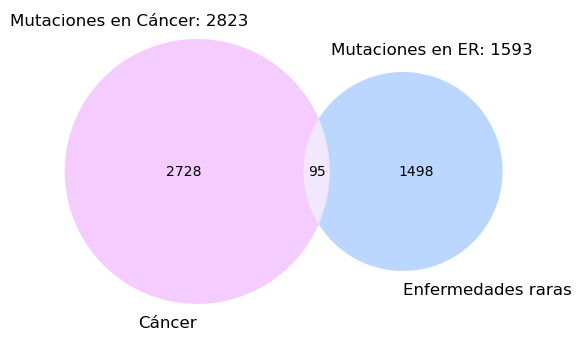

In [84]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

# Combinar las columnas 'aa_mutation' y 'Gen_names' en df_cancer
mutaciones_df1 = set(df_cancer.apply(lambda x: (x['aa_mutation'], x['Gen_names']), axis=1).unique())

# Combinar las columnas 'aa_mutation' y 'GeneSymbol' en rare_disease_variations
mutaciones_df2 = set(rare_disease_variations.apply(lambda x: (x['aa_mutation'], x['Gen_names']), axis=1).unique())

# Calcular el total de mutaciones
total_mutaciones_cancer = len(mutaciones_df1)
total_mutaciones_enfermedades_raras = len(mutaciones_df2)
mutaciones_compartidas = len(mutaciones_df1.intersection(mutaciones_df2))

# Crear el diagrama de Venn
venn2([mutaciones_df1, mutaciones_df2], set_labels=('Cáncer', 'Enfermedades raras'), set_colors=('#e580ff33', '#5599ff3b'))

# Añadir el total de mutaciones al gráfico
total_mutaciones = total_mutaciones_cancer + total_mutaciones_enfermedades_raras - mutaciones_compartidas
plt.text(-0.9, 0.5, f'Mutaciones en Cáncer: {total_mutaciones_cancer}', fontsize=12, ha='left')
plt.text(0.9, 0.4, f'Mutaciones en ER: {total_mutaciones_enfermedades_raras}', fontsize=12, ha='right')

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/tesis/ven_merge_{0}.svg".format(family_name), format='svg')

# Mostrar el diagrama
plt.show()

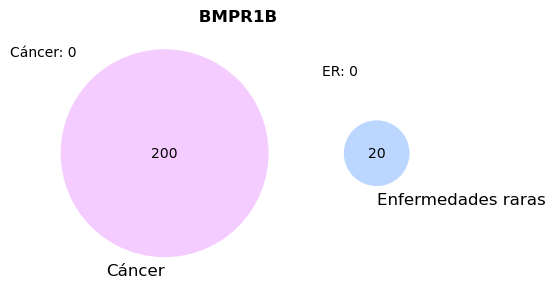

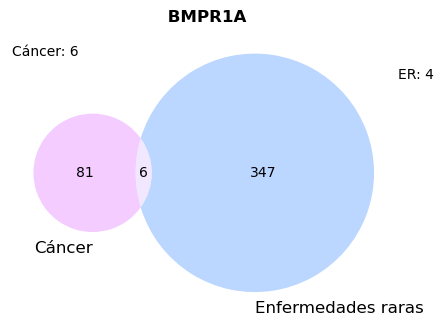

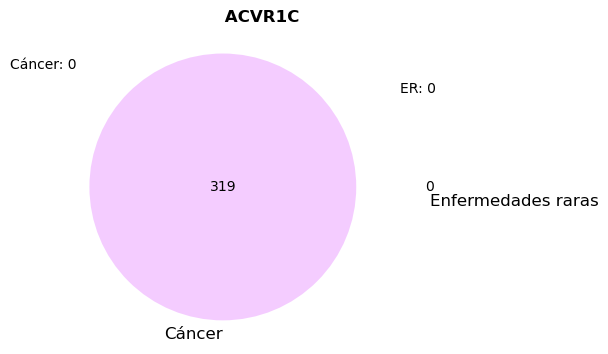

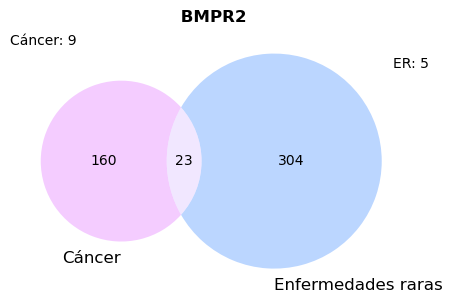

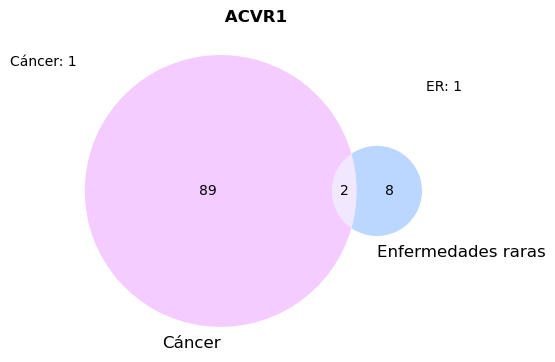

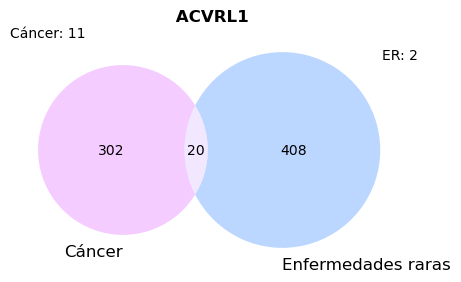

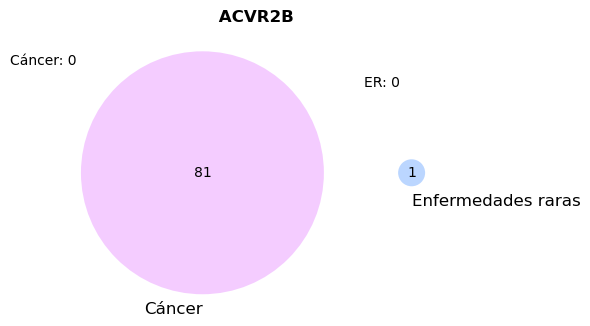

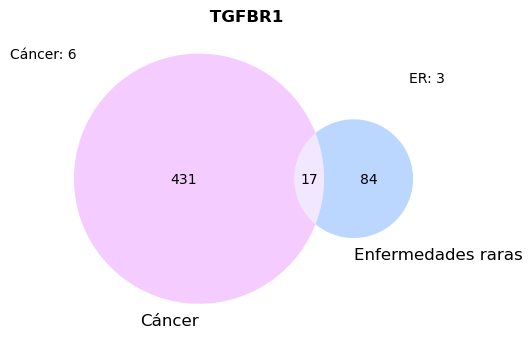

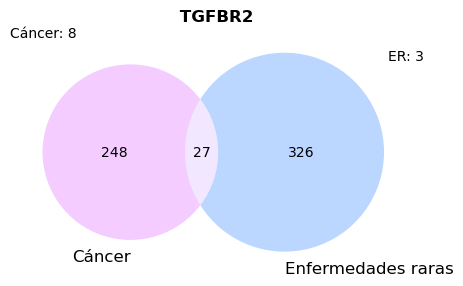

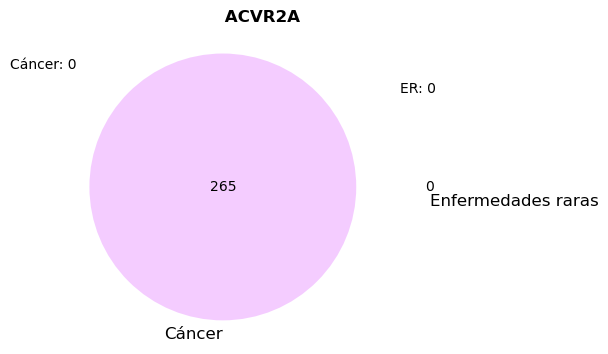

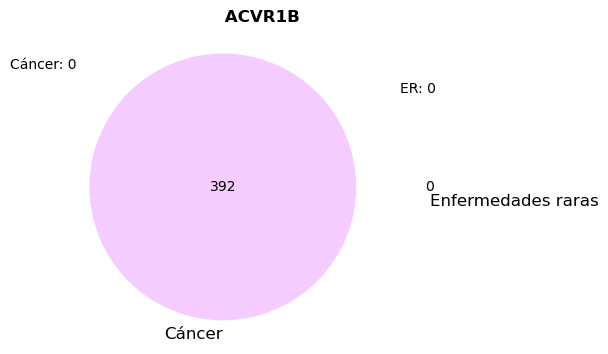

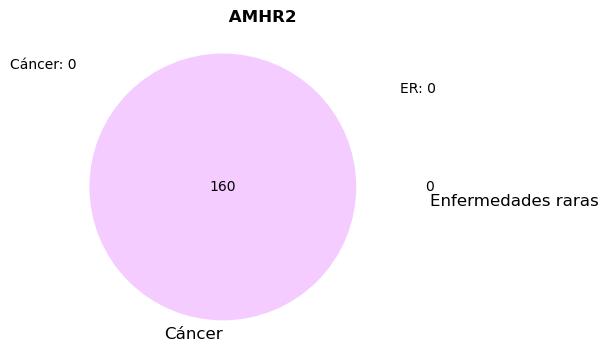

In [85]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

# Obtener lista de genes en ambos datasets
genes_cancer = set(df_cancer["Gen_names"].unique())
genes_raras = set(rare_disease_variations["Gen_names"].unique())

# Genes presentes en al menos un dataset
genes_unicos = genes_cancer.union(genes_raras)

# Crear un diagrama de Venn para cada gen
for gen in genes_unicos:
    # Obtener mutaciones por gen en ambos datasets
    mutaciones_cancer = set(df_cancer[df_cancer["Gen_names"] == gen]["aa_mutation"].unique())
    mutaciones_raras = set(rare_disease_variations[rare_disease_variations["Gen_names"] == gen]["aa_mutation"].unique())

    #tipos_cancer = set(df_cancer[df_cancer["Gen_names"] == gen]["tipo_cancer"].unique())
    #tipos_raras = set(rare_disease_variations[rare_disease_variations["Gen_names"] == gen]["Condition"].unique())

    tipos_cancer = set(df_merge_genes[df_merge_genes["Gen_names"] == gen]["tipo_cancer"].unique())
    tipos_raras = set(df_merge_genes[df_merge_genes["Gen_names"] == gen]["Condition"].unique())


    # Si no hay mutaciones en ninguno, saltar
    if not mutaciones_cancer and not mutaciones_raras:
        continue

    # Crear el diagrama de Venn
    plt.figure(figsize=(5, 5))
    venn2([mutaciones_cancer, mutaciones_raras], set_labels=('Cáncer', 'Enfermedades raras'), set_colors=('#e580ff33', '#5599ff3b'))

    # Añadir el título con el nombre del gen
    plt.title(f" {gen}", fontsize=12, fontweight='bold')

    
    # Añadir los totales
    plt.text(-0.9, 0.5, f'Cáncer: {len(tipos_cancer)}', fontsize=10, ha='left')
    plt.text(0.9, 0.4, f'ER: {len(tipos_raras)}', fontsize=10, ha='right')

    # Guardar el gráfico en formato PNG
    plt.savefig(f"../run/imagenes/tesis/venn_{gen}.svg", format='svg')
   

In [86]:
import pandas as pd


# Encontrar mutaciones comunes considerando tanto el gen como la mutación
mutaciones_comunes = set(zip(df_cancer['Gen_names'], df_cancer['aa_mutation'])).intersection(
    set(zip(rare_disease_variations['Gen_names'], rare_disease_variations['aa_mutation']))
)

# Crear DataFrame con las mutaciones comunes
df_comun = pd.DataFrame(mutaciones_comunes, columns=['Gen_names', 'aa_mutation'])

# Filtrar ambos DataFrames para obtener solo las mutaciones comunes específicas de cada gen
df_comun_cancer = pd.merge(df_cancer, df_comun, on=['Gen_names', 'aa_mutation'])
df_comun_rare = pd.merge(rare_disease_variations, df_comun, on=['Gen_names', 'aa_mutation'])

# Combinar la información adicional si es necesario
df_combinado = pd.merge(df_comun_cancer, df_comun_rare, on=['Gen_names', 'aa_mutation'], suffixes=('_cancer', '_rare'))

# Mostrar el DataFrame resultante
df_combinado


,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio,Origen_cancer,Condition(s),Molecular consequence,Condition,Origen_rare
0,ACVR1,DO219766,R206H,missense_variant,Utero,52.0,24.0,ALK2,Tipo I,GS,DataFrame 1,Progressive myositis ossificans,missense variant,FOP,DataFrame 2
1,ACVR1,DO219782,R206H,missense_variant,Utero,57.0,29.0,ALK2,Tipo I,GS,DataFrame 1,Progressive myositis ossificans,missense variant,FOP,DataFrame 2
2,ACVR1,DO40978,G356D,missense_variant,Utero,72.0,27.0,ALK2,Tipo I,Kinasa,DataFrame 1,Progressive myositis ossificans,missense variant,FOP,DataFrame 2
3,ACVR1,DO41422,G356D,missense_variant,Utero,18.0,8.0,ALK2,Tipo I,Kinasa,DataFrame 1,Progressive myositis ossificans,missense variant,FOP,DataFrame 2
4,ACVR1,DO41839,R206H,missense_variant,Utero,296.0,110.0,ALK2,Tipo I,GS,DataFrame 1,Progressive myositis ossificans,missense variant,FOP,DataFrame 2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,TGFBR2,DO8384,R553C,missense_variant,Colon,37.0,12.0,TGFBR2,Tipo II,Otro,DataFrame 1,Loeys-Dietz syndrome 2,missense variant,LDS,DataFrame 2
277,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1,Loeys-Dietz syndrome,nonsense,LDS,DataFrame 2
278,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1,Loeys-Dietz syndrome 2,nonsense,LDS,DataFrame 2
279,TGFBR2,DO8594,R522*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1,Loeys-Dietz syndrome,nonsense,LDS,DataFrame 2


In [87]:
df_combinado['aa_mutation'].nunique()

94

In [88]:
df_combinado[df_combinado['aa_mutation']=='R361*']

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio,Origen_cancer,Condition(s),Molecular consequence,Condition,Origen_rare
42,BMPR1A,DO43306,R361*,stop_gained,Utero,105.0,17.0,ALK3,Tipo I,Kinasa,DataFrame 1,"Polyposis syndrome, hereditary mixed, 2",nonsense,HMPS2,DataFrame 2
43,BMPR1A,DO43306,R361*,stop_gained,Utero,105.0,17.0,ALK3,Tipo I,Kinasa,DataFrame 1,Generalized juvenile polyposis/juvenile polypo...,nonsense,JPSC,DataFrame 2
44,BMPR1A,DO43306,R361*,stop_gained,Utero,105.0,17.0,ALK3,Tipo I,Kinasa,DataFrame 1,Hereditary cancer-predisposing syndrome,nonsense,HCPS,DataFrame 2
45,BMPR1A,DO43306,R361*,stop_gained,Utero,105.0,17.0,ALK3,Tipo I,Kinasa,DataFrame 1,Juvenile polyposis syndrome,nonsense,JPS,DataFrame 2


In [89]:
df_cancer

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio,Origen
0,ACVR1,DO10132,C81Y,missense_variant,Colon,33.0,6.0,ALK2,Tipo I,Activina,DataFrame 1
1,ACVR1,DO10880,D403N,missense_variant,Cerebro,98.0,49.0,ALK2,Tipo I,Kinasa,DataFrame 1
2,ACVR1,DO10880,V214A,missense_variant,Cerebro,101.0,52.0,ALK2,Tipo I,Kinasa,DataFrame 1
3,ACVR1,DO13522,L337S,missense_variant,Cerebro,67.0,50.0,ALK2,Tipo I,Kinasa,DataFrame 1
4,ACVR1,DO14208,W412L,missense_variant,Cabeza,34.0,3.0,ALK2,Tipo I,Kinasa,DataFrame 1
...,...,...,...,...,...,...,...,...,...,...,...
3316,TGFBR2,DO8490,R403H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3317,TGFBR2,DO8490,R428H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3318,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3319,TGFBR2,DO8594,R522*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1


In [90]:
df_cancer

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio,Origen
0,ACVR1,DO10132,C81Y,missense_variant,Colon,33.0,6.0,ALK2,Tipo I,Activina,DataFrame 1
1,ACVR1,DO10880,D403N,missense_variant,Cerebro,98.0,49.0,ALK2,Tipo I,Kinasa,DataFrame 1
2,ACVR1,DO10880,V214A,missense_variant,Cerebro,101.0,52.0,ALK2,Tipo I,Kinasa,DataFrame 1
3,ACVR1,DO13522,L337S,missense_variant,Cerebro,67.0,50.0,ALK2,Tipo I,Kinasa,DataFrame 1
4,ACVR1,DO14208,W412L,missense_variant,Cabeza,34.0,3.0,ALK2,Tipo I,Kinasa,DataFrame 1
...,...,...,...,...,...,...,...,...,...,...,...
3316,TGFBR2,DO8490,R403H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3317,TGFBR2,DO8490,R428H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3318,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3319,TGFBR2,DO8594,R522*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1


In [91]:
df_mut_cancer = df_cancer[['Gen_names', 'aa_mutation']]

# archivo excel con las mutaciones

In [92]:
import pandas as pd
import os

family_name = 'STKR'
# Crear una nueva carpeta para guardar el archivo Excel
output_dir = '../data/resultado_crossroad/resultado_genes_{0}'.format(family_name)
os.makedirs(output_dir, exist_ok=True)

# Crear un diccionario para almacenar las hojas del archivo Excel
excel_data = {}

# Crear un diccionario para almacenar las mutaciones por gen
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Condition(s)', 'aa_mutation', 'Molecular consequence']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence', 'Condition(s)']).size().reset_index(name='Count')
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[
        (df_cancer['aa_mutation'].isin(rare)) &
        (df_cancer['Gen_names'] == gen)
    ]
    rare = rare[['Gen_names', 'aa_mutation',  'tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_cancer = rare.groupby(['Gen_names', 'aa_mutation', 'tipo_cancer']).size().reset_index(name='Count')
    
    # Unir los DataFrames de enfermedades raras y cáncer
    df_gen = pd.merge(group_rare, group_cancer, on=['Gen_names', 'aa_mutation'], how='outer')
    
    # Agregar el DataFrame al diccionario de hojas
    excel_data[gen] = df_gen

# Guardar el archivo Excel con múltiples hojas
output_file = os.path.join(output_dir, 'resultado_genes.xlsx')
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    for gen, df in excel_data.items():
        df.to_excel(writer, sheet_name=gen[:31], index=False)  # Limitar nombre de hoja a 31 caracteres

print(f'Archivo Excel guardado en: {output_file}')


Archivo Excel guardado en: ../data/resultado_crossroad/resultado_genes_STKR\resultado_genes.xlsx


In [93]:
import pandas as pd
import os

family_name = 'STKR'
# Crear una nueva carpeta para guardar el archivo Excel
output_dir = '../data/resultado_crossroad_{0}/resultado_genes'.format(family_name)
os.makedirs(output_dir, exist_ok=True)

# Crear un DataFrame vacío para almacenar el resultado combinado
df_cross_variations = pd.DataFrame()

# Crear un diccionario para almacenar las mutaciones por gen
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Condition(s)', 'aa_mutation', 'Molecular consequence','Condition']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence', 'Condition(s)','Condition']).size().reset_index(name='Count')
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[
        (df_cancer['aa_mutation'].isin(rare)) &
        (df_cancer['Gen_names'] == gen)
    ]
    rare = rare[['Gen_names', 'aa_mutation', 'tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_cancer = rare.groupby(['Gen_names', 'aa_mutation', 'tipo_cancer']).size().reset_index(name='Count')
    
    # Unir los DataFrames de enfermedades raras y cáncer
    df_gen = pd.merge(group_rare, group_cancer, on=['Gen_names', 'aa_mutation'], how='outer')
    
    # Acumular los resultados en df_cross_variations
    df_cross_variations = pd.concat([df_cross_variations, df_gen], ignore_index=True)

# Guardar el DataFrame combinado en un archivo Excel
output_file = os.path.join(output_dir, 'resultado_cross_variations.xlsx')
df_cross_variations.to_excel(output_file, index=False)

print(f'Archivo Excel guardado en: {output_file}')


Archivo Excel guardado en: ../data/resultado_crossroad_STKR/resultado_genes\resultado_cross_variations.xlsx


In [94]:
import altair as alt
alt.Chart(df_cross_variations
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','Condition', 'aa_mutation']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Condition', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
     tooltip=['count(unique_aa_mutation):Q', 'Gen_names', 'Condition(s)' ]
).properties(
    title="Numero de mutaciones compartidas en cancer y enfermedades raras"
)


alt.Chart(...)

In [95]:
 alt.Chart(df_cross_variations
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','tipo_cancer', 'aa_mutation']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
     tooltip=['count(unique_aa_mutation):Q', 'Gen_names', 'tipo_cancer' ]
).properties(
    title="Numero de mutaciones compartidas en cancer y enfermedades raras"
) 

alt.Chart(...)

In [96]:
 alt.Chart(tgfbr2
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','tipo_cancer', 'aa_mutation','Condition']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color=alt.Color('Condition', scale=alt.Scale(scheme='category20')),
     tooltip=['count(unique_aa_mutation):Q', 'Gen_names', 'tipo_cancer', 'aa_mutation']
).properties(
    title="Mutaciones en TGFBR2"
) 

alt.Chart(...)

In [97]:
alt.Chart(df_cross_variations
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','tipo_cancer', 'aa_mutation', 'Condition']
).mark_bar().encode(
    x=alt.X('tipo_cancer',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    y=alt.Y('count(unique_aa_mutation):Q').title('Numero de mutaciones'),
    facet=alt.Facet('Gen_names').columns(2),
    color=alt.Color('Condition', scale=alt.Scale(scheme='category20')),
    tooltip=['Gen_names', 'tipo_cancer', 'count(unique_aa_mutation):Q','Condition(s)']
).properties(
    title='Mutaciones por gen en cada tipo de cancer',
    width=250,
    height=60
)

alt.Chart(...)

# busqueda a mano de las mutaciones de cancer en enfermeedades raras

In [98]:

# Diccionario con las listas de mutaciones para cada gen
# en el archivo 04.mut_x_cancer_icgc.ipynb se realizo una busqueda de las 20 mutaciones mas frecuentes en cada gen
mutaciones_por_gen = {

    'TGFBR2': ['R205*', 'R375*', 'R400*', 'R460*', 'R494*', 'R495*', 'R496*', 'R504*', 'R520*', 'R531*', 'R556*']
}

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones
    cross_road = rare_disease_variations[rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)]
    cross_road = cross_road[['Gen_names', 'Condition(s)', 'aa_mutation','Molecular consequence','Condition']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_counts_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence','Condition(s)','Condition']).size()
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[(df_cancer['aa_mutation'].isin(mutation_frecuentes)) & (df_cancer['Gen_names'] == gen)]
    rare = rare[['Gen_names', 'aa_mutation','tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_counts_cancer = rare.groupby(['Gen_names', 'aa_mutation','tipo_cancer']).size()
    
    # Mostrar los resultados para el gen actual
    print(f'Resultados para el gen {gen}:')
    
    if group_counts_rare.empty:
        print('Enfermedades Raras: sin coincidencias')
    else:
        print('Enfermedades Raras:')
        print(group_counts_rare)
    
    print()
    
    if group_counts_cancer.empty:
        print('Cáncer: sin coincidencias')
    else:
        print('Cáncer:')
        print(group_counts_cancer)
    
    print('\n' + '='*50 + '\n')  # Separador entre genes


Resultados para el gen TGFBR2:
Enfermedades Raras:
Gen_names  aa_mutation  Molecular consequence  Condition(s)                                        Condition
BMPR1A     R494*        nonsense               Hereditary cancer-predisposing syndrome             HCPS         1
                                               Juvenile polyposis syndrome                         JPS          1
TGFBR2     R205*        nonsense               Colorectal cancer, hereditary nonpolyposis, type 6  HNPCC6       1
                                               Loeys-Dietz syndrome                                LDS          1
                                               Loeys-Dietz syndrome 2                              LDS          1
           R375*        nonsense               Colorectal cancer, hereditary nonpolyposis, type 6  HNPCC6       1
                                               Loeys-Dietz syndrome                                LDS          1
                                          

In [99]:
df_cancer

,Gen_names,icgc_donor_id,aa_mutation,consequence_type,tipo_cancer,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,Dominio,Origen
0,ACVR1,DO10132,C81Y,missense_variant,Colon,33.0,6.0,ALK2,Tipo I,Activina,DataFrame 1
1,ACVR1,DO10880,D403N,missense_variant,Cerebro,98.0,49.0,ALK2,Tipo I,Kinasa,DataFrame 1
2,ACVR1,DO10880,V214A,missense_variant,Cerebro,101.0,52.0,ALK2,Tipo I,Kinasa,DataFrame 1
3,ACVR1,DO13522,L337S,missense_variant,Cerebro,67.0,50.0,ALK2,Tipo I,Kinasa,DataFrame 1
4,ACVR1,DO14208,W412L,missense_variant,Cabeza,34.0,3.0,ALK2,Tipo I,Kinasa,DataFrame 1
...,...,...,...,...,...,...,...,...,...,...,...
3316,TGFBR2,DO8490,R403H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3317,TGFBR2,DO8490,R428H,missense_variant,Colon,180.0,7.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3318,TGFBR2,DO8594,R497*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1
3319,TGFBR2,DO8594,R522*,stop_gained,Colon,110.0,15.0,TGFBR2,Tipo II,Kinasa,DataFrame 1


In [100]:
# Diccionario con las listas de mutaciones para cada gen
mutaciones_por_gen = {
    'TGFBR2': ['R205*', 'R375*', 'R400*', 'R460*', 'R494*', 'R495*', 'R496*', 'R504*', 'R520*', 'R531*', 'R556*'],
    'BMPR2' : ['L287*', 'R147*', 'R211*', 'R899*', 'W414*', 'W466*'],
    'BMPR1B': ['R214S', 'R244S'],
    'BMPR1A': ['L15fs', 'L317fs', 'L59*', 'R228*', 'R361*', 'R9*', 'Y407*'],
    'TGFBR1': ['R410W', 'R487W', 'R491W', 'S164L', 'S241L', 'S245L']
    
}

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Condition(s)', 'aa_mutation', 'Molecular consequence', 'Condition']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_counts_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence', 'Condition(s)', 'Condition']).size()
    
    # Filtrar y extraer las mutaciones presentes en el conjunto de datos de cáncer
    rare_mutations = cross_road['aa_mutation'].unique()
    cancer_data = df_cancer[
        (df_cancer['aa_mutation'].isin(rare_mutations)) & 
        (df_cancer['Gen_names'] == gen)
    ]
    cancer_data = cancer_data[['Gen_names', 'aa_mutation']]
    
    # Realizar un merge para incluir la enfermedad rara asociada
    cancer_data_with_rare = pd.merge(
        cancer_data,
        cross_road[['aa_mutation', 'Condition(s)']],  # Incluir solo columnas necesarias para el merge
        on='aa_mutation',
        how='left'
    )

    # Agrupar y contar las ocurrencias para el cáncer con enfermedad rara asociada
    group_counts_cancer = cancer_data_with_rare.groupby(
        ['Gen_names', 'aa_mutation', 'Condition(s)']
    ).size()
    
    # Mostrar los resultados para el gen actual
    print(f'Resultados para el gen {gen}:\n')
    
    if group_counts_rare.empty:
        print('Enfermedades Raras: sin coincidencias')
    else:
        print('Enfermedades Raras:')
        print(group_counts_rare)
    
    print()
    
    if group_counts_cancer.empty:
        print('Cáncer: sin coincidencias')
    else:
        print('Cáncer:')
        print(group_counts_cancer)
    
    print('\n' + '='*50 + '\n')  # Separador entre genes


Resultados para el gen TGFBR2:

Enfermedades Raras:
Gen_names  aa_mutation  Molecular consequence  Condition(s)                                        Condition
TGFBR2     R205*        nonsense               Colorectal cancer, hereditary nonpolyposis, type 6  HNPCC6       1
                                               Loeys-Dietz syndrome                                LDS          1
                                               Loeys-Dietz syndrome 2                              LDS          1
           R375*        nonsense               Colorectal cancer, hereditary nonpolyposis, type 6  HNPCC6       1
                                               Loeys-Dietz syndrome                                LDS          1
                                               Loeys-Dietz syndrome 2                              LDS          1
           R400*        nonsense               Colorectal cancer, hereditary nonpolyposis, type 6  HNPCC6       1
                                         

In [101]:
df_cancer.columns

Index(['Gen_names', 'icgc_donor_id', 'aa_mutation', 'consequence_type',
       'tipo_cancer', 'total_read_count', 'mutant_allele_read_count', 'Alias',
       'tipo_receptor', 'Dominio', 'Origen'],
      dtype='object')

# busca mutaciones en el data frame de cancer que coincidan con la de enfermedades raras

In [102]:
df_mut_cancer = df_cancer[['Gen_names', 'aa_mutation']]

In [103]:


# Crear un diccionario para almacenar las mutaciones por gen
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Condition(s)', 'aa_mutation', 'Molecular consequence','Condition']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_counts_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence', 'Condition(s)','Condition']).size()
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[df_cancer['aa_mutation'].isin(rare)]
    rare = rare[['Gen_names', 'aa_mutation', 'tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_counts_cancer = rare.groupby(['Gen_names', 'aa_mutation','tipo_cancer']).size()
    
    # Obtener una lista de las mutaciones de group_counts_cancer
    mutaciones_cancer = group_counts_cancer.index.get_level_values('aa_mutation').tolist()
    
    # Mostrar los resultados en el formato solicitado
    print(f'Gen: {gen}')
    print('Lista de Mutaciones:')
    print(mutaciones_cancer)
    print('\n' + '='*50 + '\n')  # Separador entre genes


Gen: ACVR1
Lista de Mutaciones:
['G356D', 'R206H']


Gen: ACVR1B
Lista de Mutaciones:
[]


Gen: ACVR1C
Lista de Mutaciones:
[]


Gen: ACVR2A
Lista de Mutaciones:
[]


Gen: ACVR2B
Lista de Mutaciones:
[]


Gen: ACVRL1
Lista de Mutaciones:
['D330Y', 'E224K', 'E236K', 'F425L', 'G350S', 'L381P', 'P378H', 'R144*', 'R200W', 'R200W', 'R374W', 'R386H', 'R411Q', 'R411Q', 'R484Q', 'R67Q', 'S462*', 'S462*', 'T277M', 'T277M', 'V441M', 'W406*', 'W420*', 'W472*']


Gen: AMHR2
Lista de Mutaciones:
[]


Gen: BMPR1A
Lista de Mutaciones:
['R361*', 'R361*', 'R361*', 'R361*', 'Q22*', 'R228*', 'R273*', 'R273*', 'R361*', 'R494*', 'W504*', 'R273*']


Gen: BMPR1B
Lista de Mutaciones:
[]


Gen: BMPR2
Lista de Mutaciones:
['R147*', 'R147*', 'W298*', 'A24E', 'C420R', 'C420Y', 'E386G', 'E98*', 'N126S', 'Q450*', 'Q6*', 'Q82H', 'R147*', 'R211*', 'R213*', 'R213*', 'R321*', 'R321*', 'R332*', 'R491W', 'R491W', 'R873*', 'R873*', 'S779*', 'W16*', 'W298*', 'W9*', 'Y113C', 'Y214*', 'Y282*', 'R491W', 'R491W', 'Y214*']


Ge

# guarda el data frame anterior

In [104]:
rare_disease_variations

,Gen_names,Condition(s),aa_mutation,Molecular consequence,Condition,Origen
0,ACVR1,Progressive myositis ossificans,R258G,missense variant,FOP,DataFrame 2
1,ACVR1,Progressive myositis ossificans,L196P,missense variant,FOP,DataFrame 2
2,ACVR1,Progressive myositis ossificans,R202I,missense variant,FOP,DataFrame 2
3,ACVR1,Progressive myositis ossificans,R375P,missense variant,FOP,DataFrame 2
4,ACVR1,Progressive myositis ossificans,G328E,missense variant,FOP,DataFrame 2
...,...,...,...,...,...,...
1840,TGFBR2,Loeys-Dietz syndrome 2,L317P,missense variant,LDS,DataFrame 2
1841,TGFBR2,Loeys-Dietz syndrome 2,L344P,missense variant,LDS,DataFrame 2
1842,TGFBR2,Loeys-Dietz syndrome 2,L369P,missense variant,LDS,DataFrame 2
1843,TGFBR2,"Colorectal cancer, hereditary nonpolyposis, ty...",A535fs,frameshift variant,HNPCC6,DataFrame 2


In [105]:
df_mut_cancer

,Gen_names,aa_mutation
0,ACVR1,C81Y
1,ACVR1,D403N
2,ACVR1,V214A
3,ACVR1,L337S
4,ACVR1,W412L
...,...,...
3316,TGFBR2,R403H
3317,TGFBR2,R428H
3318,TGFBR2,R497*
3319,TGFBR2,R522*


In [106]:
rare

,Gen_names,aa_mutation,tipo_cancer
2976,TGFBR2,R528H,Colon
2977,TGFBR2,R553H,Colon
2978,TGFBR2,D446N,Colon
2979,TGFBR2,D471N,Colon
2984,TGFBR2,D446N,Colon
...,...,...,...
3307,TGFBR2,R553H,Colon
3310,TGFBR2,R528C,Colon
3311,TGFBR2,R553C,Colon
3318,TGFBR2,R497*,Colon


In [111]:
import pandas as pd

# Crear un DataFrame vacío para almacenar los resultados
df_concat_rare = pd.DataFrame(columns=['Gen_names', 'aa_mutation','tipo_cancer', 'Condition(s)', 'Molecular_consequence', 'Condition'])

# Crear un diccionario para almacenar las mutaciones por gen
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Condition(s)', 'aa_mutation','Molecular consequence', 'Condition']]
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer para el gen específico
    rare = df_cancer[(df_cancer['aa_mutation'].isin(mutation_frecuentes)) & (df_cancer['Gen_names'] == gen)]
    rare = rare[['Gen_names', 'aa_mutation', 'tipo_cancer', 'Dominio']]
    
    # Iterar sobre cada mutación en enfermedades raras y combinar con el cáncer correspondiente
    for idx, row in cross_road.iterrows():
        aa_mut = row['aa_mutation']
        
        # Filtrar solo las filas del mismo gen y mutación en el conjunto de datos de cáncer
        matching_cancer = rare[rare['aa_mutation'] == aa_mut]
        
        for _, cancer_row in matching_cancer.iterrows():
            # Crear un DataFrame temporal con la fila que queremos agregar
            new_row = pd.DataFrame({
                'Gen_names': [row['Gen_names']],
                'aa_mutation': [row['aa_mutation']],
                'tipo_cancer': [cancer_row['tipo_cancer']],
                'Condition(s)': [row['Condition(s)']],
                'Molecular_consequence': [row['Molecular consequence']],
                'Condition': [row['Condition']],
                
            })
            
            # Concatenar el nuevo DataFrame con los resultados
            df_concat_rare = pd.concat([df_concat_rare, new_row], ignore_index=True)

# Eliminar duplicados en el DataFrame final
df_concat_rare = df_concat_rare.drop_duplicates(subset=['Gen_names', 'aa_mutation', 'tipo_cancer', 'Condition(s)', 'Molecular_consequence', 'Condition'])

# Mostrar el DataFrame resultante
print(df_concat_rare.shape)
df_concat_rare



(224, 6)


,Gen_names,aa_mutation,tipo_cancer,Condition(s),Molecular_consequence,Condition
0,ACVR1,G356D,Utero,Progressive myositis ossificans,missense variant,FOP
2,ACVR1,R206H,Utero,Progressive myositis ossificans,missense variant,FOP
7,ACVRL1,P378H,Pulmon,"Telangiectasia, hereditary hemorrhagic, type 2",missense variant,HHT
8,ACVRL1,E224K,Seno,"Telangiectasia, hereditary hemorrhagic, type 2",missense variant,HHT
9,ACVRL1,T277M,Colon,"Telangiectasia, hereditary hemorrhagic, type 2",missense variant,HHT
...,...,...,...,...,...,...
275,TGFBR2,R553H,Pancreas,Loeys-Dietz syndrome,missense variant,LDS
276,TGFBR2,R553H,Estomago,Loeys-Dietz syndrome,missense variant,LDS
278,TGFBR2,R537H,Utero,Loeys-Dietz syndrome,missense variant,LDS
279,TGFBR2,R562C,Pancreas,Loeys-Dietz syndrome 2,missense variant,LDS


In [112]:
print(f"Número de mutaciones en cáncer: {df_cancer.groupby('Gen_names')['aa_mutation'].nunique().sum()}")
print(f"Numero de mutaciones patogenicas: {rare_disease_variations.groupby('Gen_names')['aa_mutation'].nunique().sum()}")
print(f"Numero de mutaciones compartidas: {df_concat_rare.groupby('Gen_names')['aa_mutation'].nunique().sum()}")

Número de mutaciones en cáncer: 2823
Numero de mutaciones patogenicas: 1593
Numero de mutaciones compartidas: 95


In [113]:
rare

,Gen_names,aa_mutation,tipo_cancer,Dominio
2976,TGFBR2,R528H,Colon,Kinasa
2977,TGFBR2,R553H,Colon,Otro
2978,TGFBR2,D446N,Colon,Kinasa
2979,TGFBR2,D471N,Colon,Kinasa
2980,TGFBR2,M123I,Colon,Activina
...,...,...,...,...
3316,TGFBR2,R403H,Colon,Kinasa
3317,TGFBR2,R428H,Colon,Kinasa
3318,TGFBR2,R497*,Colon,Kinasa
3319,TGFBR2,R522*,Colon,Kinasa


In [124]:
df_concat_rare[df_concat_rare['Gen_names']=='TGFBR2']['tipo_cancer'].unique()

array(['Seno ', 'Utero', 'Colon', 'Cervix', 'Pancreas', 'Estomago',
       'Cabeza', 'Pulmon'], dtype=object)

In [116]:
df_concat_rare

,Gen_names,aa_mutation,tipo_cancer,Condition(s),Molecular_consequence,Condition
0,ACVR1,G356D,Utero,Progressive myositis ossificans,missense variant,FOP
2,ACVR1,R206H,Utero,Progressive myositis ossificans,missense variant,FOP
7,ACVRL1,P378H,Pulmon,"Telangiectasia, hereditary hemorrhagic, type 2",missense variant,HHT
8,ACVRL1,E224K,Seno,"Telangiectasia, hereditary hemorrhagic, type 2",missense variant,HHT
9,ACVRL1,T277M,Colon,"Telangiectasia, hereditary hemorrhagic, type 2",missense variant,HHT
...,...,...,...,...,...,...
275,TGFBR2,R553H,Pancreas,Loeys-Dietz syndrome,missense variant,LDS
276,TGFBR2,R553H,Estomago,Loeys-Dietz syndrome,missense variant,LDS
278,TGFBR2,R537H,Utero,Loeys-Dietz syndrome,missense variant,LDS
279,TGFBR2,R562C,Pancreas,Loeys-Dietz syndrome 2,missense variant,LDS


In [117]:
# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
df_unique = df_concat_rare.drop_duplicates(subset=['Gen_names', 'aa_mutation','tipo_cancer','Condition(s)','Condition'])

# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
mutation_frequencies_cancer_rare = df_unique.groupby(['Gen_names','tipo_cancer','Condition(s)','Condition']).size().reset_index(name='mutation_count')


# Paso 3: Mostrar los resultados
mutation_frequencies_cancer_rare.sort_values(ascending=False, by='mutation_count')

,Gen_names,tipo_cancer,Condition(s),Condition,mutation_count
75,TGFBR2,Pancreas,Loeys-Dietz syndrome 2,LDS,10
73,TGFBR2,Pancreas,Loeys-Dietz syndrome,LDS,9
82,TGFBR2,Utero,Loeys-Dietz syndrome 2,LDS,8
31,BMPR2,Colon,Primary pulmonary hypertension,PPH,7
49,TGFBR1,Colon,Multiple self-healing squamous epithelioma,MSSE,6
...,...,...,...,...,...
39,BMPR2,Riñon,Primary pulmonary hypertension,PPH,1
40,BMPR2,Seno,"Pulmonary hypertension, primary, 1",PPH1,1
1,ACVRL1,Cabeza,"Telangiectasia, hereditary hemorrhagic, type 2",HHT,1
42,BMPR2,Utero,Pulmonary arterial hypertension,PAH,1


In [57]:
df_concat_rare.columns

Index(['Gen_names', 'aa_mutation', 'VariationID', 'tipo_cancer',
       'Condition(s)', 'Molecular_consequence', 'Condition'],
      dtype='object')

In [58]:
df_merge_genes = df_merge_genes[['Gen_names', 'aa_mutation', 'VariationID', 'tipo_cancer',
       'Condition(s)','Condition', 'Dominio']]
df_merge_genes

KeyError: "['VariationID'] not in index"

In [59]:
# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
df_unique = df_merge_genes.drop_duplicates(subset=['Gen_names', 'aa_mutation','tipo_cancer','Condition(s)','Condition','Dominio'])

# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
mutation_frequencies_cancer_rare2 = df_unique.groupby(['Gen_names','Dominio','tipo_cancer']).nunique().reset_index()


# Paso 3: Mostrar los resultados
mutation_frequencies_cancer_rare2.sort_values(ascending=False, by='aa_mutation')

,Gen_names,Dominio,tipo_cancer,icgc_donor_id,aa_mutation,consequence_type,total_read_count,mutant_allele_read_count,Alias,tipo_receptor,GeneSymbol,Condition(s),Protein change,Molecular consequence,Condition
49,TGFBR2,Kinasa,Pancreas,7,10,2,7,7,1,1,1,5,10,2,3
52,TGFBR2,Kinasa,Utero,5,10,2,6,5,1,1,1,3,10,2,1
27,BMPR2,Kinasa,Colon,7,7,2,7,6,1,1,1,4,7,2,4
38,TGFBR1,Kinasa,Estomago,2,6,1,2,2,1,1,1,2,6,1,1
47,TGFBR2,Kinasa,Colon,4,6,2,4,4,1,1,1,3,6,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25,BMPR2,Activina,Utero,1,1,1,1,1,1,1,1,1,1,1,1
26,BMPR2,Kinasa,Cerebro,1,1,1,1,1,1,1,1,1,1,1,1
1,ACVR1,Kinasa,Utero,1,1,1,1,1,1,1,1,1,1,1,1
32,BMPR2,Otro,Estomago,1,1,1,1,1,1,1,1,2,1,1,2


In [ ]:
mutation_frequencies_cancer_rare2.sum()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
#ordered_cancer = mutation_frequencies_cancer_rare.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index
ordered_disease = mutation_frequencies_cancer_rare.groupby('Condition')['mutation_count'].sum().sort_values(ascending=False).index
ordered_cancer = ['Utero', 'Colon', 'Piel', 'Pulmon', 'Pancreas', 'Estomago', 'Higado','Seno ', 'Cabeza', 'Cerebro', 'Vejiga', 'Ovario', 'Cervix', 'Riñon', 'Vesicula', 'Prostata', 'Sangre', 'Hueso']


# Obtener lista de genes 
genes = df_cancer["Gen_names"].unique()


# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = mutation_frequencies_cancer_rare.pivot_table(
    index='tipo_cancer',
    columns='Condition',
    values='mutation_count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(index=ordered_cancer, columns=ordered_disease)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=False, fmt=".0f", cbar_kws={'label': 'Número de Mutaciones'})

# Ajustar las etiquetas  para que estén horizontales
plt.gca().set_yticklabels(plt.gca().get_yticklabels(), rotation=0)
plt.gca().set_xticklabels(plt.gca().get_xticklabels(), rotation=45, ha='right')  # Rotar las etiquetas y alinearlas a la derecha

# Añadir título y etiquetas
plt.title("Heatmap: Número de mutaciones en comun entre Cáncer y Enfermedades Raras", weight='bold')
plt.xlabel("Enfermedades Raras")
plt.ylabel("Tipo de Cáncer")

# Ajustar automáticamente el diseño para evitar texto cortado
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/tesis/heatmap_cancer_merge_rd_{0}.svg".format(family_name), format='svg')

# Mostrar el gráfico
plt.show()

In [ ]:
mutation_frequencies_cancer_rare

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import math

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
ordered_disease = mutation_frequencies_cancer_rare.groupby('Condition')['mutation_count'].sum().sort_values(ascending=False).index
ordered_cancer = ['Utero', 'Colon', 'Piel', 'Pulmon', 'Pancreas', 'Estomago', 'Higado', 'Seno', 'Cabeza', 'Cerebro', 
                  'Vejiga', 'Ovario', 'Cervix', 'Riñon', 'Vesicula', 'Prostata', 'Sangre', 'Hueso']

# Obtener lista de genes
genes = mutation_frequencies_cancer_rare["Gen_names"].unique()

# Definir el número de filas y columnas del grid
n_rows, n_cols = 3, 2  
n_plots_per_figure = n_rows * n_cols  # 6 gráficos por imagen

# Calcular cuántas figuras serán necesarias
n_figures = math.ceil(len(genes) / n_plots_per_figure)

# Iterar sobre los subconjuntos de genes
for fig_idx in range(n_figures):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 18))  # Tamaño ajustado
    axes = axes.flatten()  # Convertir en lista para indexar fácilmente

    # Seleccionar los genes para esta figura
    subset_genes = genes[fig_idx * n_plots_per_figure : (fig_idx + 1) * n_plots_per_figure]

    for i, gene in enumerate(subset_genes):
        # Filtrar los datos para el gen actual
        gene_data = mutation_frequencies_cancer_rare[mutation_frequencies_cancer_rare["Gen_names"] == gene]

        # Pivotear el DataFrame para el formato del heatmap
        heatmap_data = gene_data.pivot_table(
            index='tipo_cancer',
            columns='Condition',
            values='mutation_count',
            aggfunc='sum'
        ).reindex(index=ordered_cancer, columns=ordered_disease)

        # Crear el heatmap en la subfigura correspondiente
        sns.heatmap(heatmap_data, cmap="YlGnBu", annot=False, fmt=".0f", cbar_kws={'label': 'N° Mutaciones'}, ax=axes[i])

        # Ajustar título del subplot
        axes[i].set_title(f"{gene}", weight='bold', fontsize=14)
        axes[i].set_xlabel("Enfermedades Raras", fontsize=10)
        axes[i].set_ylabel("Tipo de Cáncer", fontsize=10)

        # Ajustar etiquetas de los ejes
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].tick_params(axis='y', rotation=0)

    # Eliminar ejes vacíos si hay menos de 6 genes en la figura actual
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    # Ajustar el layout y guardar
    plt.tight_layout()
    #plt.savefig(f"../run/imagenes/tesis/heatmap_cancer_merge_rd_page_{fig_idx+1}.svg", format='svg')
    plt.savefig(f"../run/imagenes/tesis/heatmap_cancer_merge_rd_page_{fig_idx+1}.png", format='png', dpi=600)

    # Mostrar la figura
    plt.show()


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
#ordered_cancer = mutation_frequencies_cancer_rare.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index
ordered_disease = mutation_frequencies_cancer_rare.groupby('Gen_names')['mutation_count'].sum().sort_values(ascending=False).index
ordered_cancer = ['Utero', 'Colon', 'Piel', 'Pulmon', 'Pancreas', 'Estomago', 'Higado','Seno ', 'Cabeza', 'Cerebro', 'Vejiga', 'Ovario', 'Cervix', 'Riñon', 'Vesicula', 'Prostata', 'Sangre', 'Hueso']

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = mutation_frequencies_cancer_rare.pivot_table(
    columns='tipo_cancer',
    index='Gen_names',
    values='mutation_count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(columns=ordered_cancer, index=ordered_disease)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={'label': 'Número de Mutaciones'})

# Ajustar las etiquetas  para que estén horizontales
plt.gca().set_yticklabels(plt.gca().get_yticklabels(), rotation=0)
plt.gca().set_xticklabels(plt.gca().get_xticklabels(), rotation=45, ha='right')  # Rotar las etiquetas y alinearlas a la derecha

# Añadir título y etiquetas
plt.title("Heatmap: Number of mutations in common with Cancer and Rare Diseases")
plt.ylabel("Rare Diseases")
plt.xlabel("Cancer type")

# Ajustar automáticamente el diseño para evitar texto cortado
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
#plt.savefig("../run/imagenes/heatmap_cancer_rd_{0}.png".format(family_name), format='png', dpi=600)

# Mostrar el gráfico
plt.show()

In [ ]:
mutation_frequencies_cancer_rare2

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Supongamos que df_variaciones ya está definido y contiene las columnas necesarias
# Agrupar por tipo de cáncer para contar las mutaciones totales
mutation_counts = mutation_frequencies_cancer_rare2.groupby('Dominio', as_index=False)['aa_mutation'].sum()

# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by='aa_mutation', ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts['aa_mutation'].cumsum() / mutation_counts['aa_mutation'].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 6))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts['Dominio'], mutation_counts["aa_mutation"])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts['Dominio'], mutation_counts['aa_mutation'], color="#e9d8ffff", label='Numero de mutaciones')

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color="red", marker="p", ms=5, label='Acumulacion relativa porcentual')

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=10)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color='purple', fontsize=11,fontweight  = 'bold')
# Ajustar límites y etiquetas
ax.set_ylabel('Numero de mutaciones')
ax2.set_ylabel('Acumulacion relativa porcentual')
ax.set_title('Numero de mutaciones y Acumulacion relativa porcentual por Dominio')
ax.set_xlabel('Dominios')

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts['Dominio'])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts['Dominio'], rotation=45, ha="right")  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='center right', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='center right', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/Tesis/barras_mutation_merge_DOMINIO_{0}.svg".format(family_name), format='svg')

plt.show()


In [ ]:
mutation_frequencies_cancer_rare2.sum()

# almacena las mutaciones coincidentes y crea un script para correr en pymol

In [ ]:
df_mut_cancer

In [ ]:
rare_disease_variations

In [ ]:
import os

# Crear un diccionario para almacenar las mutaciones por gen en cáncer
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Define la carpeta donde se guardarán los archivos
family_name = 'STKR'
output_folder = f'../run/scripts_pymol_{family_name}'

# Crear la carpeta si no existe
os.makedirs(output_folder, exist_ok=True)

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Condition(s)', 'aa_mutation', 'VariationID','Molecular consequence']]
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[
        (df_cancer['aa_mutation'].isin(rare)) &
        (df_cancer['Gen_names'] == gen)
    ]
    rare_mutations = rare['aa_mutation'].unique()

    # Nombre del archivo .py
    file_name = f"{gen}.py"
    
    # Ruta completa del archivo
    file_path = os.path.join(output_folder, file_name)
    
    # Contenido del archivo
    with open(file_path, 'w') as f:
        f.write(f"# Script de PyMOL para el gen {gen}\n")
        f.write("from pymol import cmd\n\n")
        f.write("cmd.bg_color(color='white')\n")
        f.write("cmd.orient()\n")# Orienta la proteína al origen
        f.write("cmd.set('cartoon_transparency', 0.4)\n")
        f.write("cmd.color('aquamarine', 'all')\n")  # Colorea la proteína en cian
        for mutation in rare_mutations:
            mutation_number = ''.join(filter(str.isdigit, mutation))
            f.write(f"cmd.select('{mutation}', 'resi {mutation_number}')\n")
            f.write(f"cmd.show('sticks', '{mutation}')\n")  # Muestra la mutación en estilo sticks (varillas)
            #f.write(f"cmd.label('''byca({mutation})''', 'oneletter+resi')\n")
            f.write(f"cmd.label('resi {mutation_number}', '{mutation}')\n")
            f.write(f"cmd.color('lightmagenta', 'resi {mutation_number}')\n\n") # Colorea el residuo mutado en rojo
        
    
    print(f"Archivo {file_name} guardado exitosamente en {output_folder}")

print("Todos los archivos de scripts se han generado correctamente.")


In [ ]:
import os

# Crear un diccionario para almacenar las mutaciones por gen en cáncer
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Define la carpeta donde se guardarán los archivos
family_name = 'STKR'
output_folder = f'../run/scripts_pymol_{family_name}'

# Crear la carpeta si no existe
os.makedirs(output_folder, exist_ok=True)

# Diccionario de aminoácidos
aminoacidos = {
    'A': 'ALA',  # Alanina
    'R': 'ARG',  # Arginina
    'N': 'ASN',  # Asparagina
    'D': 'ASP',  # Ácido Aspártico
    'C': 'CYS',  # Cisteína
    'E': 'GLU',  # Ácido Glutámico
    'Q': 'GLN',  # Glutamina
    'G': 'GLY',  # Glicina
    'H': 'HIS',  # Histidina
    'I': 'ILE',  # Isoleucina
    'L': 'LEU',  # Leucina
    'K': 'LYS',  # Lisina
    'M': 'MET',  # Metionina
    'F': 'PHE',  # Fenilalanina
    'P': 'PRO',  # Prolina
    'S': 'SER',  # Serina
    'T': 'THR',  # Treonina
    'W': 'TRP',  # Triptófano
    'Y': 'TYR',  # Tirosina
    'V': 'VAL'   # Valina
}

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Condition(s)', 'aa_mutation', 'VariationID', 'Molecular consequence']]
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[
        (df_cancer['aa_mutation'].isin(rare)) &
        (df_cancer['Gen_names'] == gen)
    ]
    rare_mutations = rare['aa_mutation'].unique()

    # Nombre del archivo .py
    file_name = f"{gen}.py"
    
    # Ruta completa del archivo
    file_path = os.path.join(output_folder, file_name)
    
    # Contenido del archivo
    with open(file_path, 'w') as f:
        f.write(f"# Script de PyMOL para el gen {gen}\n")
        f.write("from pymol import cmd\n\n")
        f.write("cmd.bg_color(color='white')\n")
        f.write("cmd.orient()\n")  # Orienta la proteína al origen
        f.write("cmd.set('cartoon_transparency', 0.4)\n")
        f.write("cmd.color('aquamarine', 'all')\n")  # Colorea la proteína en cian
        
        for mutation in rare_mutations:
            # Extraer número de la mutación
            mutation_number = ''.join(filter(str.isdigit, mutation))
            
            # Extraer el aminoácido mutado (última letra) y mapear a su abreviatura de tres letras
            mutated_residue_one_letter = mutation[-1]
            mutated_residue_three_letter = aminoacidos.get(mutated_residue_one_letter, 'Unknown')
            
            f.write(f"cmd.select('{mutation}', 'resi {mutation_number}')\n")
            f.write("cmd.wizard('mutagenesis')\n")  # Inicia el asistente de mutagénesis
            f.write(f"cmd.get_wizard().set_mode('{mutated_residue_three_letter}')\n")  # Configurar el aminoácido mutado
            f.write(f"cmd.get_wizard().do_select('resi {mutation_number}')\n")  # Selecciona el residuo
            f.write("cmd.get_wizard().apply()\n")  # Aplica la mutación
            f.write(f"cmd.show('sticks', 'resi {mutation_number}')\n")  # Muestra la mutación en estilo sticks (varillas)
           # f.write(f"cmd.label('resi {mutation_number}', 'oneletter+resi')\n")
            f.write(f"cmd.select('{mutated_residue_three_letter+mutation_number}', 'resi {mutation_number}')\n")
            f.write(f"cmd.label('''byca({mutated_residue_three_letter})''', 'oneletter+resi')\n")
            f.write(f"cmd.color('lightmagenta', 'resi {mutation_number}')\n\n")  # Colorea el residuo mutado en magenta
        
    print(f"Archivo {file_name} guardado exitosamente en {output_folder}")

print("Todos los archivos de scripts se han generado correctamente.")


In [ ]:
family_code = 'IPR000333'
df_kinasa=pd.read_csv('../data/Genes/df_kinasa_{0}.csv'.format(family_code))
df_kinasa.shape

In [ ]:
uniprot_id = df_kinasa['Uniprot ID'].unique()
uniprot_id

# obtiene la secuencia fasta de las proteinas

# adaptar el data frame para hacer grafico lolipop

In [ ]:
df_concat_rare

In [ ]:
df_concat_rare['aa_mutation'].nunique()

In [ ]:
import pandas as pd

# Definir una función para extraer los números de la mutación
def extract_pos(aa_mutation):
    return ''.join(filter(str.isdigit, aa_mutation))

# Aplicar la función a la columna 'aa_mutation' y crear la nueva columna 'mutation_location'
df_concat_rare['pos'] = df_concat_rare['aa_mutation'].apply(extract_pos)

# Mostrar el DataFrame resultante
df_concat_rare


In [ ]:
df_concat_rare.groupby('Gen_names')['aa_mutation'].nunique()

In [ ]:
#interpro_code = 'IPR000333'
family_name = 'STKR'
ruta = '../data/mutaciones/mutaciones_crossroad_{0}.csv'.format(family_name)
df_concat_rare.to_csv(ruta, index=False)

In [ ]:
import pandas as pd

# Función para extraer la letra izquierda y derecha de la mutación
def extract_ref_mut(aa_mutation):
    # Extraer la posición (números)
    mutation_number = ''.join(filter(str.isdigit, aa_mutation))
    
    # Encontrar la posición de los números en la cadena
    number_index = aa_mutation.find(mutation_number)
    
    # Extraer la letra izquierda y derecha
    ref = aa_mutation[number_index - 1] if number_index > 0 else None
    mutation = aa_mutation[number_index + len(mutation_number)] if number_index + len(mutation_number) < len(aa_mutation) else None
    
    return ref, mutation

# Aplicar la función y crear las nuevas columnas 'pos' y 'ref'
df_concat_rare[['ref', 'mutation']] = df_concat_rare['aa_mutation'].apply(lambda x: pd.Series(extract_ref_mut(x)))

# Eliminar duplicados

df_concat_rare.drop_duplicates(['Gen_names', 'aa_mutation', 'VariationID','tipo_cancer', 'Condition(s)',
       'Molecular_consequence', 'pos', 'ref', 'mutation'], inplace=True)

# Mostrar el DataFrame resultante
df_concat_rare


In [ ]:
df_concat_rare[df_concat_rare['aa_mutation']=='R528C']

In [ ]:
df_concat_rare[df_concat_rare['aa_mutation']=='R528H']

In [ ]:
dom_mutations = df_concat_rare[df_concat_rare['pos'] > '200' ]
print(len(dom_mutations))
dom_mutations

In [ ]:
# Obtener combinaciones únicas de las columnas 'aa_mutation' y 'VariationID' como una lista de tuplas
unique_mutations_list = dom_mutations[['Gen_names','aa_mutation', 'VariationID']].drop_duplicates().values.tolist()
unique_mutations_list


In [ ]:
df_concat_rare.columns

In [ ]:
df_nuevo = df_concat_rare[['Gen_names', 'aa_mutation', 'Molecular_consequence', 'pos', 'ref', 'mutation']]
df_nuevo

In [ ]:
interpro_code = 'IPR000333'
uniprot_code =  pd.read_csv('../data/Genes/df_kinasa_{0}.csv'.format(interpro_code))

In [ ]:
uniprot_code

In [ ]:
df_nuevo = df_concat_rare.merge(uniprot_code[['Uniprot ID', 'Gen_names']], left_on='Gen_names', right_on='Gen_names')
df_nuevo.shape

In [ ]:
df_nuevo.rename(columns={'Uniprot ID': 'uniprotid'}, inplace=True)

In [ ]:
df_nuevo=df_nuevo[['Gen_names','aa_mutation','uniprotid', 'pos', 'ref', 'mutation']]
print(df_nuevo.shape)
df_nuevo

In [ ]:
df_nuevo.drop_duplicates(['Gen_names','aa_mutation','uniprotid', 'pos', 'ref', 'mutation'], inplace=True)
df_nuevo.shape

In [ ]:
df_nuevo['size'] = '0'

In [ ]:
#visualizar en https://www.bioinformatics.com.cn/plot_basic_lollipop_mutation_diagram_090_en
df_nuevo

In [ ]:
import pandas as pd

family_name = 'STKR'

# Crear un archivo Excel y guardar cada gen en una hoja diferente
with pd.ExcelWriter('../run/mutaciones_crossroad/mutaciones_lolipop_{0}.xlsx'.format(family_name), engine='xlsxwriter') as writer:
    for gene in df_nuevo['Gen_names']:
        # Filtrar las filas correspondientes a ese gen
        df_gen = df_nuevo[df_nuevo['Gen_names'] == gene]
        # Guardar cada gen en una hoja diferente con el nombre del gen
        df_gen.to_excel(writer, sheet_name=gene[:31], index=False)  # El nombre de la hoja no puede tener más de 31 caracteres



In [ ]:
family_name = 'STKR'
# Guarda el DataFrame en un archivo Excel
df_nuevo.to_excel('../run/mutaciones_crossroad/mutaciones_lolipop_{0}.xlsx'.format(family_name), index=False)

# Tabla cancer/ER

In [ ]:
df_concat_rare

In [ ]:
df_concat_rare.columns

In [ ]:
df_tabla_merge = df_concat_rare[['Gen_names','aa_mutation', 'Condition','tipo_cancer' ]]
df_tabla_merge

In [ ]:
df_tabla_merge[df_tabla_merge.duplicated(keep=False)]


In [ ]:
tabla_limpia = df_tabla_merge.drop_duplicates()
print(f"Numero de mutaciones compartidas: {tabla_limpia.groupby('Gen_names')['aa_mutation'].nunique().sum()}")
tabla_limpia

In [ ]:
tabla_limpia.to_excel("tabla_limpia.xlsx", index=False)


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import math

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
ordered_disease = mutation_frequencies_cancer_rare.groupby('Condition')['mutation_count'].sum().sort_values(ascending=False).index
ordered_cancer = ['Utero', 'Colon', 'Piel', 'Pulmon', 'Pancreas', 'Estomago', 'Higado', 'Seno', 'Cabeza', 'Cerebro', 
                  'Vejiga', 'Ovario', 'Cervix', 'Riñon', 'Vesicula', 'Prostata', 'Sangre', 'Hueso']

# Obtener lista de genes
genes = mutation_frequencies_cancer_rare["Gen_names"].unique()

# Definir el número de filas y columnas del grid
n_rows, n_cols = 3, 2  
n_plots_per_figure = n_rows * n_cols  # 6 gráficos por imagen

# Calcular cuántas figuras serán necesarias
n_figures = math.ceil(len(genes) / n_plots_per_figure)

# Iterar sobre los subconjuntos de genes
for fig_idx in range(n_figures):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 18))  # Tamaño ajustado
    axes = axes.flatten()  # Convertir en lista para indexar fácilmente

    # Seleccionar los genes para esta figura
    subset_genes = genes[fig_idx * n_plots_per_figure : (fig_idx + 1) * n_plots_per_figure]

    for i, gene in enumerate(subset_genes):
        # Filtrar los datos para el gen actual
        gene_data = mutation_frequencies_cancer_rare[mutation_frequencies_cancer_rare["Gen_names"] == gene]

        # Pivotear el DataFrame para el formato del heatmap
        heatmap_data = gene_data.pivot_table(
            index='tipo_cancer',
            columns='Condition',
            values='mutation_count',
            aggfunc='sum'
        ).reindex(index=ordered_cancer, columns=ordered_disease)

        # Crear el heatmap en la subfigura correspondiente
        sns.heatmap(heatmap_data, cmap="YlGnBu", annot=False, fmt=".0f", cbar_kws={'label': 'N° Mutaciones'}, ax=axes[i])

        # Ajustar título del subplot
        axes[i].set_title(f"{gene}", weight='bold', fontsize=14)
        axes[i].set_xlabel("Enfermedades Raras", fontsize=10)
        axes[i].set_ylabel("Tipo de Cáncer", fontsize=10)

        # Ajustar etiquetas de los ejes
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].tick_params(axis='y', rotation=0)

    # Eliminar ejes vacíos si hay menos de 6 genes en la figura actual
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    # Ajustar el layout y guardar
    plt.tight_layout()
    plt.savefig(f"../run/imagenes/tesis/heatmap_cancer_merge_rd_page_{fig_idx+1}.svg", format='svg')

    # Mostrar la figura
    plt.show()
